# Trabalho Prático 1 - Busca exaustiva

Este documento é parte da primeira avaliação prática da disciplina de inteligência artificial ministrada em 2024 na UFMT.

O tema do trabalho é a aplicação do algoritmo $A\star$ no quebra-cabeça de 8 peças.


**Esta é uma atividade individual. Escreva sua própria solução.**
---


# Quebra-cabeça de 8-peças

O quebra-cabeça de oito peças consiste em uma matriz $3 \times 3$ com $8$ (oito) células quadradas rotuladas  de $1$ a $8$ e uma célula em branco. O objetivo do jogo é reorganizar as células para que elas fiquem em ordem. É permitido mover as células horizontalmente ou verticalmente (mas não diagonalmente) para o quadrado em branco.

Um exemplo de seqüência de movimentos válidos com uma solução é apresentada a seguir.

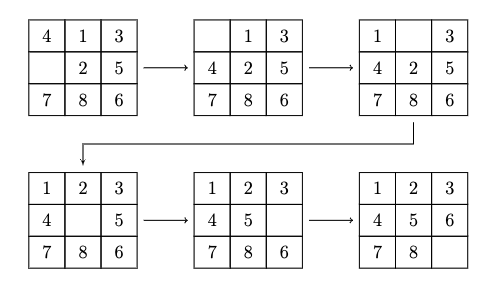


# Tarefas

Esse trabalho é dividido em quatro tarefas:

1. **Remoção de estados repetitivos:** você alterar a função A* para não considerar estados já visitados.
2. **Detecção de jogos sem resposta:** você deve implementar uma função que recebe um estado e verificar se o estado ordenado é alcançálvel a partir dele.
3. **Comparação de heurísticas:** você deve comparar quantitavamente as heurísticas.
4. **Análise e Experimentos:** você deve criar um experimento para responder uma pergunta de sua escolha sobre o jogo ou algoritmo.


# Notas e Critérios de Correção



A nota do trabalho é a soma da pontuação das quatro tarefas.
A pontuação de cada tarefa é indicada na Tabela 1.

| Tarefa                                   | Pontuação      |
| -----------------------------------------| -------------- |
| 1. Não inclusão de estados repetidos     | **1.0 pontos** |
| 2. Detecção de jogos sem resposta        | **1.5 pontos** |
| 3. Comparação de heurísticas             | **2.5 pontos** |
| 4. Análise e Experimentos                | **5.0 pontos** |
|**Total**                                 |**10.0 pontos** |

Na comparação de heurísticas, você deve definir um critério (métrica) e realizar uma análise quantitaiva com base nesse critério. O critério pode ser: a) tempo para encontrar resposta ou b) número de estados enfileirados, por exemplo. Escolha o que julgar mais adequado.   

No item ''Análise e Experimentos'', você deve escolher algum aspecto do jogo ou do algoritmo para analisar. Esse processo consiste em definir uma pergunta e um experimento para respondê-la.

Escolha uma pergunta sobre algo que te deixou curioso. Por exemplo, você entendeu por que alguns jogos não tem resposta? Ou por que uma heurística é melhor que a outra? Pensou em uma nova heurística.

Um ponto de partida sugerido é testar o algoritmo $A\star$ para os estados:

1. \begin{bmatrix} 4 & 1 & 3 \\
   & 2 & 5\\
 7 & 8 & 6\end{bmatrix}


2. \begin{bmatrix}  & 1 & 3 \\
  4 & 2 & 5\\
 7 & 8 & 6\end{bmatrix}


3. \begin{bmatrix} 4 &  & 5 \\
  3 & 8 & 6\\
 7 & 1 & 2\end{bmatrix}



4. \begin{bmatrix} 5 & 3 & 2 \\
  7 & 6 & 4\\
 8 & 1 & \end{bmatrix}


5. \begin{bmatrix} 4 & 6 & 7 \\
   & 5 & 8\\
 2 & 1 & 3\end{bmatrix}


Você deve obrigatoriamente **apresentar** os resultados de seu achados para o professor.

## Importante:



A avaliação desta tarefa levará em conta a interpretação dos resultados dos testes de comparação. Sua interpretação deve propor e responder perguntas utilizando o que foi observado experimentalmente.


# Implementação do Quebra-cabeça de 8-peças

Essa seção contém os códigos que tratam da [representação de estados](#scrollTo=k46QXsCjbVKs) e aplicação das [regras do jogo](#scrollTo=y5KuKUZDddDr).




Antes de começar, carregue os pacotes.

In [ ]:
import numpy as np
from scipy.signal import convolve2d as conv2
import matplotlib
from queue import PriorityQueue

## Representação

Cada estado do jogo é uma matriz 3 x 3 contendo os números $1, \ldots 9$,  $9$ indica uma célula em branco.

O _tipo_ `Estado` cria estados do jogo. Esse tipo tem atributos (`d` e `p`) que facilitam a manipulação da Fila de Prioridades.

In [ ]:
class Estado:
  def __init__(self, pai=None, matriz=None):
      self.pai = pai
      self.matriz = matriz

      self.d = 0 # tamanho do caminho inicio - estado
      self.c = 0 #
      self.p = 0 # prioridade

  def __eq__(self, other):
      return len(self.matriz[np.where(self.matriz!= other.matriz)]) == 0

  def __lt__(self, other):
    return self.p<other.p

  def mostrar(self):
    for i in self.matriz:
      print(i)
    print()


Estados são criados utilizando o _construtor_. Uma vez criado, o `Estado` é visualizado com o método `mostrar`.

Os comandos abaixo ilustram isso para o estado
\begin{bmatrix} 4 & 1 & 3 \\
   & 2 & 5\\
 7 & 8 & 6 \end{bmatrix}

In [ ]:
estado = Estado(matriz=np.array([[4, 1, 3], [9, 2, 5],[7, 8, 6]]))
estado.p = 1
estado2 = Estado(matriz=np.array([[4, 1, 3], [9, 2, 5],[7, 8, 6]]))
estado2.p = 2
print(estado < estado2)
estado.mostrar()

True
[4 1 3]
[9 2 5]
[7 8 6]



## Regras de movimentação

Um movimento válido é um deslocamento  horizontal ou vertical de um célula para o quadrado branco. Duas funções implementação essa regra: `acoes_permitidas` e `movimentar`.

A função `acoes_permitidas` recebe um estado e devolve a lista de células que podem ser movimentadas.

Já a função `movimentar` recebe um estado `s` e uma celula `c` e devolve o estado após a movimentação de `c`.

In [ ]:
def acoes_permitidas(estado):

  adj = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]])
  blank = estado.matriz==9
  mask = conv2(blank, adj, 'same')

  return estado.matriz[np.where(mask)]

O código abaixo mostra que é possível movimentar as células $2$, $4$, $5$ e $8$ para o estado

\begin{bmatrix} 1 & 2 & 3 \\
  4 &   & 5\\
 7 & 8 & 6\end{bmatrix}


In [ ]:
s = Estado(matriz=np.array([[1, 2, 3], [4, 9, 5],[7, 8, 6]]))
print("Acoes permitidas ", acoes_permitidas(s))

Acoes permitidas  [2 4 5 8]


In [ ]:
def movimentar(s, c):

  matriz = s.matriz.copy()

  matriz[np.where(s.matriz==9)] = c
  matriz[np.where(s.matriz==c)] = 9

  return Estado(matriz=matriz)

## Vizinhança

O exemplo abaixo mostra com  combinar as funções `acoes_permitidas` e `movimentar` para produzir a vizinhança de um estado.  

In [ ]:
s = Estado(matriz=np.array([[1, 2, 3], [4, 9, 5],[7, 8, 6]]))
s.mostrar()
for acao in acoes_permitidas(s):
  v = movimentar(s, acao)
  v.mostrar()

[1 2 3]
[4 9 5]
[7 8 6]

[1 9 3]
[4 2 5]
[7 8 6]

[1 2 3]
[9 4 5]
[7 8 6]

[1 2 3]
[4 5 9]
[7 8 6]

[1 2 3]
[4 8 5]
[7 9 6]



# Heurísticas


## Definição Manhattan

A distância [_Manhattan_](https://pt.wikipedia.org/wiki/Geometria_do_t%C3%A1xi) é a soma das distâncias horizontal e vertical entre cada célula e sua posição correta.

A Figura 2 abaixo ilustra o resultado para o estado

\begin{bmatrix} 4 & 1 & 3 \\
  8 & 2 & 5\\
 7 &  & 6\end{bmatrix}



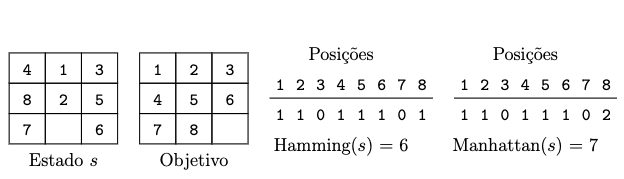
Figura 2 - Exemplo de distâncias

A distância é medida em células.
O número $8$, por exemplo, está há duas células de distância de sua posição correta. O número $5$ está há apenas 1.


In [ ]:
estado = Estado(matriz=np.array([[4, 6, 7], [9, 5, 8],[2, 1, 3]]))
obj = np.array([[1,2,3], [4,5,6], [7,8,9]])

def dist(t1, t2):
  return np.sum(list(map(lambda i, j: abs(i - j), t1, t2)))

def manhattan(estado, obj):
  return np.sum([dist(np.where(obj==i), np.where(estado.matriz==i)) for i in range(1,9)])

manhattan(estado, obj)

17

## Definição Hamming

A heurística Hamming mede a quantidade de células fora do lugar.

In [ ]:
def hamming(s):
  obj = np.array([[1,2,3], [4,5,6], [7,8,9]])
  qtde_fora_lugar = len(s.matriz[np.where(s.matriz != obj)])
  # 9 não pode entrar na conta
  return (qtde_fora_lugar-1 if qtde_fora_lugar > 0 else
          0)



 $A\star$



In [ ]:
def astar(s, f, o):

  Q = PriorityQueue()

  s.p = 0
  Q.put((s.p, s))


  while not Q.empty():
    v = Q.get()[1]

    if v==o:
      return v


    for a in acoes_permitidas(v):
      u = movimentar(v, a)

      u.d = v.d + 1
      u.pai = v
      u.p = f(u)+u.d
      Q.put((u.p, u))

  return s

o = Estado(matriz=np.array([[1, 2, 3], [4, 5, 6],[7, 8, 9]]))
s = Estado(matriz=np.array([[1, 2, 3], [4, 9, 5],[7, 8, 6]]))
v = astar(s, hamming, o)
v.mostrar()
print(v.d)

[1 2 3]
[4 5 6]
[7 8 9]

2


# Detecção de Estados sem solução



Alguns estados do jogo não podem ser reorganizada para que suas células fiquem em ordem.
Este é o caso, por exemplo, da matriz ilustada a seguir.

\begin{bmatrix} 1 & 2 & 3 \\
  4 & 5 & 6\\
 8 & 7 & \end{bmatrix}

 Para identicar um jogo sem solução, você pode explorar o fato de que os estados deste jogo são divididas em duas classes:
 1. aquelas que podem ser resolvidas e
 2. aquelas que só podem ser resolvidas se qualquer par de células adjacentes e não vazias for trocado.